# Uczenie Maszynowe 1 - Klasyfikatory liniowe - metoda SVM
**Wojciech Olejnik**

**Cel laboratorium:**
Celem jest zaimplementowanie metody SVM z wykorzystaniem standardowych procedur optymalizacji z ograniczeniami oraz analizą działania algorytmu. Implementacja zostanie wykonana za pomoca bibioteki **_cvxopt_**

In [1]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
import matplotlib.pyplot as plt
import time
from sklearn.metrics import accuracy_score
import pandas as pd
from numpy import linalg as LA
import cvxopt
import warnings
warnings.filterwarnings("ignore")
from linear_classifiers import LinBase, PerceptronMargin, Perceptron, AveragedPerceptron, VotedPerceptron, plotClass

**Implementacja klasy _LinSvm_ dla danych liniowo separowalnych**

In [19]:
class LinSvm(LinBase):

    def __init__(self, **kwargs):
        super(LinSvm, self).__init__(**kwargs)
        self.svm_inds = None
        self.name_ = 'LinSvm'

    def fit(self, X, y):
        m, n = X.shape
        p = np.diag(np.ones(n+1))
        p[-1, -1] = 0
        q = np.zeros(n + 1)
        g = (-1)*np.hstack((X, np.ones((m, 1))))*np.outer(y, np.ones(n + 1))
        h = (-1) * np.ones((m, 1))

        pc = cvxopt.matrix(p)
        qc = cvxopt.matrix(q)
        gc = cvxopt.matrix(g)
        hc = cvxopt.matrix(h)

        sol = cvxopt.solvers.qp(pc, qc, gc, hc)
        print(sol)

        self.coef_ = np.array(sol['x'])[0:-1, 0]
        self.intercept_ = np.array(sol['x'])[-1, 0]
        print('SVM')
        print('coef: ', self.coef_)
        print('intercept: ', self.intercept_)
#         print('sol x: ', sol['x'])
#         print('sol z: ', sol['z'])
        self.svm_inds = np.nonzero(np.array(sol['z']) > 1)[0]
        print(f'svm_inds {self.svm_inds}')

**Implementacja klasy _LinSvmOpt_ dla danych nieliniowo separowalnych**  
Wykorzysatmo powyższą implementacja, z tą rónicą że dodano ograniczenia.

In [20]:
class LinSvmOpt(LinBase):
    def __init__(self, c=1, **kwargs):
        super(LinSvmOpt, self).__init__(**kwargs)
        self.svm_inds = None
        self.name_ = 'LinSvm'
        self.c_ = c

    def fit(self, X, y):
        m, n = X.shape
        p = np.diag(np.concatenate((np.ones(n), np.zeros(m+1))))
        q = np.zeros(n+1+m)
        q[-m:] = self.c_

        g1 = (-1)*np.hstack((X, np.ones((m, 1))))*np.outer(y, np.ones(n+1))
        g = np.vstack((np.hstack((g1, -np.diag(np.ones(m)))),
                      np.hstack((np.zeros((m, n+1)), -np.diag(np.ones(m))))))
        h = np.vstack(( (-1)*np.ones((m, 1)), (0)*np.ones((m, 1)) ))

        pc = cvxopt.matrix(p)
        qc = cvxopt.matrix(q)
        gc = cvxopt.matrix(g)
        hc = cvxopt.matrix(h)

        solve = cvxopt.solvers.qp(pc, qc, gc, hc)

        self.coef_ = np.array(solve['x'])[0:n, 0]
        self.intercept_ = np.array(solve['x'])[n, 0]
        self.ksi = np.array(solve['x'])[n+1:, 0]
        self.svm_inds_ = np.nonzero(self.ksi >= 1e-4)[0]

# Testowanie dla generowanych danych

**Testowanie klasy _LinSvm_ dla wygenerowaynych danych liniowo separowalnych**

     pcost       dcost       gap    pres   dres
 0:  3.9138e+00  4.8548e+02  2e+03  2e+00  2e+02
 1:  2.7031e+01  9.7985e+01  9e+02  1e+00  1e+02
 2:  2.7956e+01  3.6249e+02  9e+02  1e+00  1e+02
 3:  3.0889e+01  2.1069e+03  1e+03  1e+00  1e+02
 4:  3.2866e+01  4.4852e+03  1e+03  1e+00  1e+02
 5:  1.0398e+02  5.5741e+04  2e+03  1e+00  1e+02
 6:  5.2401e+02  5.4394e+04  5e+03  1e+00  1e+02
 7:  2.4229e+03  8.0672e+04  1e+04  1e+00  1e+02
 8:  1.2802e+04  1.1576e+05  3e+04  9e-01  1e+02
 9:  6.7079e+04  1.9372e+05  8e+04  7e-01  8e+01
10:  2.4340e+05  2.6997e+05  6e+04  2e-01  2e+01
11:  2.8211e+05  2.8263e+05  9e+02  3e-03  3e-01
12:  2.8280e+05  2.8280e+05  1e+01  3e-05  3e-03
13:  2.8281e+05  2.8281e+05  1e-01  3e-07  3e-05
14:  2.8281e+05  2.8281e+05  1e-03  3e-09  3e-07
15:  2.8281e+05  2.8281e+05  1e-05  3e-11  5e-08
Optimal solution found.
{'x': <3x1 matrix, tc='d'>, 'y': <0x1 matrix, tc='d'>, 's': <500x1 matrix, tc='d'>, 'z': <500x1 matrix, tc='d'>, 'status': 'optimal', 'gap': 9.5

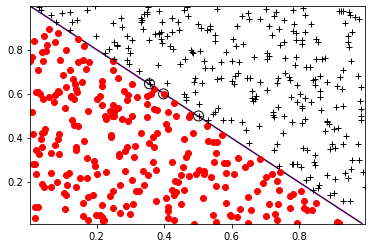

In [21]:
m, n = 500, 2
X = np.random.rand(m, n)
y = (X.dot([1, 1]) > 1) * 2 - 1

clf = LinSvm()
t1 = time.time()
clf.fit(X, y)
t2 = time.time()
print(f'Czas : {t2 - t1}')
plotClass(X, y, clf)
# print(clf.coef_, clf.intercept_)
margin, b = clf.margin(X, y)
print(f'Wartość marginesu wynosi: {margin}')
plt.show()


**Testowanie klasy _LinSvmOpt_ dla wygenerowaynych danych liniowo separowalnych**

     pcost       dcost       gap    pres   dres
 0: -3.0516e+02  1.0938e+03  5e+03  4e+00  1e+01
 1:  5.4450e+02 -2.0197e+02  1e+03  4e-01  1e+00
 2:  1.6069e+02  6.3972e+01  1e+02  3e-02  7e-02
 3:  1.2383e+02  1.0140e+02  2e+01  5e-03  1e-02
 4:  1.1859e+02  1.0837e+02  1e+01  2e-03  6e-03
 5:  1.1585e+02  1.1175e+02  4e+00  7e-04  2e-03
 6:  1.1478e+02  1.1309e+02  2e+00  1e-04  4e-04
 7:  1.1414e+02  1.1377e+02  4e-01  3e-05  7e-05
 8:  1.1400e+02  1.1391e+02  9e-02  4e-06  1e-05
 9:  1.1396e+02  1.1396e+02  3e-03  1e-07  3e-07
10:  1.1396e+02  1.1396e+02  3e-05  1e-09  3e-09
Optimal solution found.
Czas : 0.1786644458770752
Wartość marginesu wynosi: -0.018890619883035895


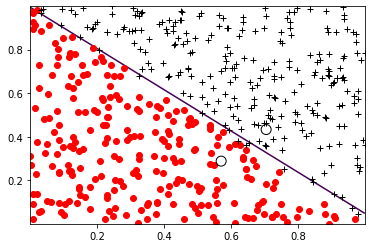

In [34]:
m, n = 500, 2
X = np.random.rand(m, n)
y = (X.dot([1, 1]) > 1) * 2 - 1

clf = LinSvmOpt()
t1 = time.time()
clf.fit(X, y)
t2 = time.time()
print(f'Czas : {t2 - t1}')
plotClass(X, y, clf)
# print(clf.coef_, clf.intercept_)
margin, b = clf.margin(X, y)
print(f'Wartość marginesu wynosi: {margin}')
plt.show()


**Ważne :** _Punkty, które nie zmienieją ograniczeń zostało oznaczone w kółko_

**Testowanie klasy _LinSvmOpt_ dla wygenerowaynych danych liniowo nieseparowalnych**

     pcost       dcost       gap    pres   dres
 0: -2.9265e+02  1.1698e+03  6e+03  4e+00  1e+01
 1:  6.1018e+02 -2.3349e+02  1e+03  5e-01  1e+00
 2:  1.7411e+02  7.8835e+01  1e+02  2e-02  4e-02
 3:  1.3591e+02  1.1353e+02  2e+01  3e-03  8e-03
 4:  1.3112e+02  1.1954e+02  1e+01  1e-03  4e-03
 5:  1.2830e+02  1.2290e+02  6e+00  6e-04  2e-03
 6:  1.2695e+02  1.2449e+02  3e+00  2e-04  6e-04
 7:  1.2614e+02  1.2539e+02  8e-01  5e-05  1e-04
 8:  1.2585e+02  1.2570e+02  2e-01  4e-06  1e-05
 9:  1.2579e+02  1.2576e+02  3e-02  7e-07  2e-06
10:  1.2578e+02  1.2577e+02  3e-03  4e-08  1e-07
11:  1.2578e+02  1.2578e+02  5e-05  9e-10  2e-09
Optimal solution found.
Czas : 0.2669038772583008
LinSvmOpt [ w=[5.3668121  5.64471606], b=-6.611584106612884 ] 
zxczxc[  4   5   6   7   9  20  21  24  26  27  35  38  44  45  47  48  51  52
  54  55  62  64  65  70  73  76  77  78  82  89  90  92  98 104 109 111
 116 118 123 124 128 131 135 136 137 138 140 142 143 150 156 165 166 170
 171 173 175 176 178 181 1

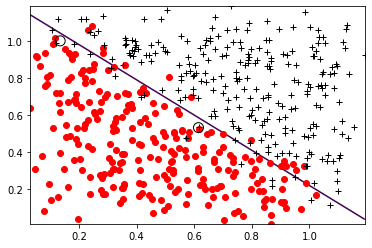

In [36]:
m, n = 500, 2

X = np.random.rand(m, n)
y = (X.dot([1, 1]) > 1) * 2 - 1
X = X + np.random.rand(m, n) * 0.2

clf = LinSvmOpt()
t1 = time.time()
clf.fit(X, y)
t2 = time.time()
print(f'Czas : {t2 - t1}')
plotClass(X, y, clf)
print(clf.__str__())
# print(clf.coef_, clf.intercept_)
print(f'zxczxc{clf.svm_inds_}')
margin, b = clf.margin(X, y)
print(f'Wartość marginesu wynosi: {margin}')
plt.show()

# Testowanie dla  danych sonar

In [23]:
sonar = pd.read_csv("sonar.csv")
X_sonar = np.array(sonar.iloc[:,0:-1])
y_sonar = np.array(sonar.iloc[:,-1])
y_sonar[y_sonar == 'Rock'] = -1
y_sonar[y_sonar == 'Mine'] = 1
print('Real y:')
print(y_sonar)

Real y:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


**Testowanie klasy _LinSvm_**

In [24]:
clf = LinSvm()
t1 = time.time()
clf.fit(X_sonar.astype(int), y_sonar.astype(int))
t2 = time.time()
print(f'Czas : {t2 - t1}')
# plotClass(X, y, clf)
# print(clf.coef_, clf.intercept_)
margin, b = clf.margin(X_sonar, y_sonar)
print(f'Wartość marginesu wynosi: {margin}')
plt.show()

     pcost       dcost       gap    pres   dres
 0:  1.7398e+00  1.8349e+02  3e+02  3e+00  1e-14
 1:  1.0982e+00  3.5204e+02  2e+01  1e+00  2e-14
 2:  1.1112e+00  5.7017e+03  6e+01  1e+00  6e-13
 3:  1.1355e+00  5.4715e+05  5e+02  1e+00  6e-11
 4:  1.1384e+00  5.8037e+08  1e+04  1e+00  7e-08
 5:  1.1385e+00  2.5481e+13  6e+06  1e+00  3e-03
 6:  1.1385e+00  1.0577e+20  3e+11  1e+00  5e+03
 7:  1.1385e+00  4.3897e+28  1e+18  1e+00  9e+11
 8:  1.1385e+00  1.5173e+39  6e+27  1e+00  5e+22
 9:  1.5708e+04  5.2627e+48  2e+37  1e+00  6e+32
10:  1.2830e+19  1.7745e+58  7e+46  1e+00  9e+41
11:  4.0013e+23  8.9087e+67  4e+56  1e+00  1e+52
12:  3.5192e+36  4.6746e+76  2e+65  4e+01  1e+61
13:  5.4107e+39  5.2980e+84  2e+73  1e+03  9e+67
14:  3.4773e+53  1.7105e+93  7e+81  7e+09  8e+76
15:  3.0231e+62  4.0412e+104  1e+92  4e+14  3e+88
16:  1.0082e+67  2.4005e+111  6e+98  3e+16  6e+94
17:  1.0534e+76  1.4284e+118  4e+105  2e+21 2e+102
18:  3.5927e+80  8.5020e+124  2e+112  2e+23 3e+108
19:  7.1750e+89

**Testowanie klasy _LinSvmOpt_ (z ograniczeniami)**

In [25]:
clf = LinSvmOpt()
t1 = time.time()
clf.fit(X_sonar.astype(int), y_sonar.astype(int))
t2 = time.time()
print(f'Czas : {t2 - t1}')
# plotClass(X, y, clf)
# print(clf.coef_, clf.intercept_)
margin, b = clf.margin(X_sonar, y_sonar)
print(f'Wartość marginesu wynosi: {margin}')
plt.show()

     pcost       dcost       gap    pres   dres
 0: -1.4449e+01  5.3975e+02  2e+03  4e+00  4e+00
 1:  3.8243e+02  1.3258e+02  2e+02  6e-16  3e-15
 2:  1.8336e+02  1.6022e+02  2e+01  4e-16  9e-16
 3:  1.7396e+02  1.7168e+02  2e+00  2e-16  1e-13
 4:  1.7292e+02  1.7281e+02  1e-01  2e-16  3e-13
 5:  1.7286e+02  1.7286e+02  1e-03  3e-16  1e-13
 6:  1.7286e+02  1.7286e+02  1e-05  3e-16  7e-13
Optimal solution found.
Czas : 0.04075121879577637
Wartość marginesu wynosi: -1.2606489206064027


# Testowanie dla  gotowej implementacji SVM z sklearn

**Testowanie dla generowanych danych**

 margin0.9000814152170886
 margin1.7704711042961956


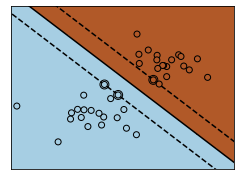

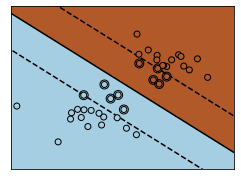

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm

# we create 40 separable points
np.random.seed(0)
X = np.r_[np.random.randn(20, 2) - [2, 2], np.random.randn(20, 2) + [2, 2]]
Y = [0] * 20 + [1] * 20

# figure number
fignum = 1

# fit the model
for name, penalty in (('unreg', 1), ('reg', 0.05)):

    clf = svm.SVC(kernel='linear', C=penalty)
    clf.fit(X, Y)

    # get the separating hyperplane
    w = clf.coef_[0]
    a = -w[0] / w[1]
    xx = np.linspace(-5, 5)
    yy = a * xx - (clf.intercept_[0]) / w[1]

    margin = 1 / np.sqrt(np.sum(clf.coef_ ** 2))
    print(f' margin{margin}')
    yy_down = yy - np.sqrt(1 + a ** 2) * margin
    yy_up = yy + np.sqrt(1 + a ** 2) * margin

    # plot the line, the points, and the nearest vectors to the plane
    plt.figure(fignum, figsize=(4, 3))
    plt.clf()
    plt.plot(xx, yy, 'k-')
    plt.plot(xx, yy_down, 'k--')
    plt.plot(xx, yy_up, 'k--')

    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=80,
                facecolors='none', zorder=10, edgecolors='k')
    plt.scatter(X[:, 0], X[:, 1], c=Y, zorder=10, cmap=plt.cm.Paired,
                edgecolors='k')

    plt.axis('tight')
    x_min = -4.8
    x_max = 4.2
    y_min = -6
    y_max = 6

    XX, YY = np.mgrid[x_min:x_max:200j, y_min:y_max:200j]
    Z = clf.predict(np.c_[XX.ravel(), YY.ravel()])

    # Put the result into a color plot
    Z = Z.reshape(XX.shape)
    plt.figure(fignum, figsize=(4, 3))
    plt.pcolormesh(XX, YY, Z, cmap=plt.cm.Paired)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    plt.xticks(())
    plt.yticks(())
    fignum = fignum + 1

plt.show()

# Podsumowanie

**LinSVM :**

|        | Dane liniowo separowalne | Dane liniowo nieseparowalne | Dane sonar           |
|--------|--------------------------|-----------------------------|----------------------|
| Time   | 0.028810739517211914     |                             | 0.11192035675048828  |
| Margin | 0.0013296607748336186    |                             | 1.041715984926612    |


**LinSVMOpt :**
    
|        | Dane liniowo separowalne | Dane liniowo nieseparowalne | Dane sonar           |
|--------|--------------------------|-----------------------------|----------------------|
| Time   | 0.1786644458770752       | 0.2669038772583008          | 0.04075121879577637  |
| Margin | -0.018890619883035895    | 0.10938312661680508         | -1.2606489206064027  |


**SKLEARN SVM  :**

|        | Dane liniowo separowalne | Dane liniowo nieseparowalne | Dane sonar           |
|--------|--------------------------|-----------------------------|----------------------|
| Time   | 0.1786644458770752       | 0.2669038772583008          | 0.2231778256219483   |
| Margin | -0.018890619883035895    | 0.10938312661680508         | 0.094172243605721  |


**Wynik perceptronu z poprzednich laboratoriów**

**PERCEPTRON :**

|            | Dane lniowe       | Dane sonar          | Dane liniowo separowalne | Dane liniowo nieseparowalne |
|------------|-------------------|---------------------|--------------------------|-----------------------------|
| Time       | 0.546633243560791 | 0.05423736572265625 | 0.05419135093688965      | 1.0000739097595215          |
| Iterations | 64014             | 5354                | 8401                     | 391081                      |
| Overrun    | No                | No                  | No                       | Yes                         |


**VOTED PERCEPTRON :**

|            | Dane lniowe        | Dane sonar         | Dane liniowo separowalne | Dane liniowo nieseparowalne |
|------------|--------------------|--------------------|--------------------------|-----------------------------|
| Time       | 10.000088453292847 | 10.000101089477539 | 10.000121593475342       | 0.16863799095153809         |
| Iterations | 1832344            | 1913471            | 4612813                  | 78408                       |
| Overrun    | Yes                | Yes                | Yes                      | No                          |

**AVERAGE PERCEPTRON :**

|            | Dane lniowe         | Dane sonar         | Dane liniowo separowalne | Dane liniowo nieseparowalne |
|------------|---------------------|--------------------|--------------------------|-----------------------------|
| Time       | 0.18581652641296387 | 10.000095844268799 | 10.000102758407593       | 0.21128559112548828         |
| Iterations | 22195               | 1788842            | 4537237                  | 78408                       |
| Overrun    | No                  | Yes                | Yes                      | No                          |



# Wnioski

* Metoda klasyfikatora liniowego SVM poradziła sobie lepiej niż Perceptron
* SVM uzyskał znacznie szybciej wyniki niż Perceptron
* Klasa LinSVM jest wolniejsza od klasy LinSVMOpt
* Dla SVM z bibioteki sklearn otrzymywane wynik są podobne
